<a href="https://colab.research.google.com/github/SobiaNoorAI/cxr-foundation-model-shift-robustness/blob/main/notebooks/02_linear_probe_and_cross_hospital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Load everything

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, os
BASE = "/content/drive/MyDrive/phd_projects/cxr_shift"
SEED = 42

df = pd.read_csv(f"{BASE}/metadata.csv")
ENC = ["resnet50_imagenet", "dinov2_base", "rad_dino"]
F = {k: np.load(f"{BASE}/features/{k}.npy") for k in ENC}

y = df.label.values
hosp = df.hospital.values
for k in ENC:
    assert F[k].shape[0] == len(df), "features and metadata are out of sync"
print(df.groupby(["hospital", "label"]).size())

Mounted at /content/drive
hospital    label
montgomery  0         80
            1         58
shenzhen    0        326
            1        336
dtype: int64


## classifier and the confidence-interval helper

In [ ]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

def make_model():
    # Scales features, then fits logistic regression.
    # The regularization strength C is chosen by inner 5-fold CV on the TRAINING data only.
    return make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], cv=5,
                             scoring="roc_auc", max_iter=5000, random_state=SEED),
    )

def boot_auc(y_true, scores, n=1000, seed=SEED):
    # Stratified bootstrap: resample normals and TB cases separately.
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    aucs = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        aucs.append(roc_auc_score(y_true[idx], scores[idx]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    return roc_auc_score(y_true, scores), lo, hi

def summarize(y_true, scores, thr=0.5):
    auc, lo, hi = boot_auc(y_true, scores)
    pred = (scores >= thr).astype(int)
    sens = ((pred == 1) & (y_true == 1)).sum() / (y_true == 1).sum()
    spec = ((pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum()
    acc = (pred == y_true).mean()
    return dict(AUROC=auc, CI_low=lo, CI_high=hi, Acc=acc, Sens=sens, Spec=spec)

## run all experiments

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

rows = []
for enc in ENC:
    X = F[enc]
    # A) Within-hospital: 5-fold cross-validated predictions
    for h in ["shenzhen", "montgomery"]:
        m = hosp == h
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
        s = cross_val_predict(make_model(), X[m], y[m], cv=skf,
                              method="predict_proba")[:, 1]
        rows.append(dict(encoder=enc, setting="within", train=h, test=h,
                         **summarize(y[m], s)))
    # B) Cross-hospital: train on one, test on the other
    for tr, te in [("shenzhen", "montgomery"), ("montgomery", "shenzhen")]:
        mdl = make_model().fit(X[hosp == tr], y[hosp == tr])
        s = mdl.predict_proba(X[hosp == te])[:, 1]
        rows.append(dict(encoder=enc, setting="cross", train=tr, test=te,
                         **summarize(y[hosp == te], s)))

res = pd.DataFrame(rows)
res.round(3)

,encoder,setting,train,test,AUROC,CI_low,CI_high,Acc,Sens,Spec
0,resnet50_imagenet,within,shenzhen,shenzhen,0.886,0.860,0.913,0.816,0.795,0.837
1,resnet50_imagenet,within,montgomery,montgomery,0.783,0.704,0.852,0.725,0.621,0.800
2,resnet50_imagenet,cross,shenzhen,montgomery,0.557,0.453,0.650,0.514,0.793,0.312
3,resnet50_imagenet,cross,montgomery,shenzhen,0.675,0.637,0.717,0.619,0.619,0.620
4,dinov2_base,within,shenzhen,shenzhen,0.913,0.891,0.936,0.850,0.845,0.856
5,dinov2_base,within,montgomery,montgomery,0.850,0.776,0.914,0.804,0.741,0.850
6,dinov2_base,cross,shenzhen,montgomery,0.836,0.762,0.900,0.732,0.397,0.975
7,dinov2_base,cross,montgomery,shenzhen,0.746,0.708,0.781,0.674,0.494,0.859
8,rad_dino,within,shenzhen,shenzhen,0.980,0.972,0.987,0.909,0.890,0.929
9,rad_dino,within,montgomery,montgomery,0.965,0.929,0.994,0.928,0.879,0.962


## save and plot

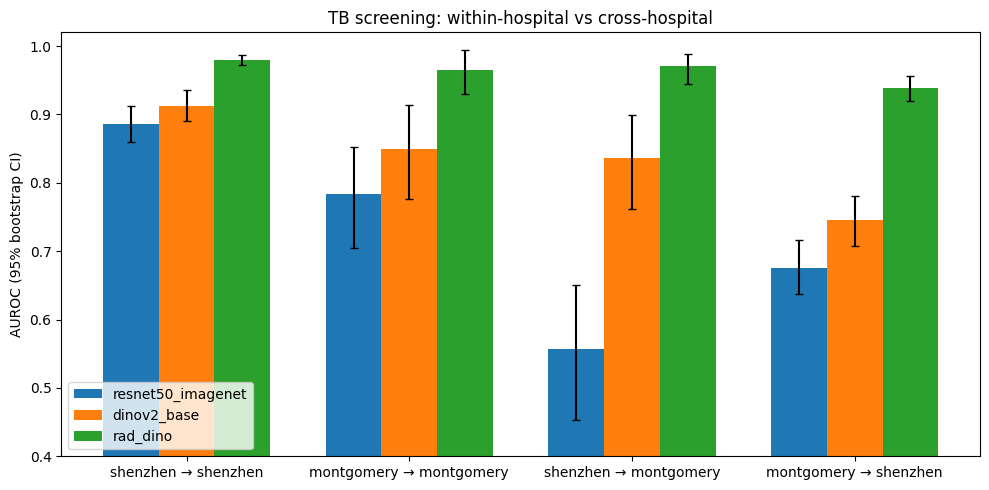

In [ ]:
import matplotlib.pyplot as plt
os.makedirs(f"{BASE}/results", exist_ok=True)
res.round(4).to_csv(f"{BASE}/results/02_probe_results.csv", index=False)

res["label"] = res.train + " → " + res.test
labels = res["label"].unique()
fig, ax = plt.subplots(figsize=(10, 5))
w = 0.25
for i, enc in enumerate(ENC):
    sub = res[res.encoder == enc].set_index("label").loc[labels]
    err = [sub.AUROC - sub.CI_low, sub.CI_high - sub.AUROC]
    ax.bar(np.arange(len(labels)) + i * w, sub.AUROC, w, yerr=err, capsize=3, label=enc)
ax.set_xticks(np.arange(len(labels)) + w)
ax.set_xticklabels(labels)
ax.set_ylabel("AUROC (95% bootstrap CI)")
ax.set_ylim(0.4, 1.02)
ax.legend()
ax.set_title("TB screening: within-hospital vs cross-hospital")
plt.tight_layout()
plt.savefig(f"{BASE}/results/02_auroc.png", dpi=200)
plt.show()